In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [55]:
df = pd.read_csv("Sample - Superstore.csv")

print(df.shape)
df.head()

(9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [56]:
# Dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

In [57]:
# Convert date columns into datetime format

df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

# Check the updated data types
df[["Order Date", "Ship Date"]].dtypes

Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object

In [58]:
# Check missing values in each column

df.isnull().sum()

# Check duplicate records

print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 0


In [59]:
# Generate statistical summary

df.describe()

,Row ID,Order Date,Ship Date,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994,9994,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,2016-04-30 00:07:12.259355,2016-05-03 23:06:58.571142,55190.379428,229.858001,3.789574,0.156203,28.656896
min,1.000000,2014-01-03 00:00:00,2014-01-07 00:00:00,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,2015-05-23 00:00:00,2015-05-27 00:00:00,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,2016-06-26 00:00:00,2016-06-29 00:00:00,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,2017-05-14 00:00:00,2017-05-18 00:00:00,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,2017-12-30 00:00:00,2018-01-05 00:00:00,99301.000000,22638.480000,14.000000,0.800000,8399.976000
std,2885.163629,NaN,NaN,32063.693350,623.245101,2.225110,0.206452,234.260108


In [60]:
# Q1: Calculate Total Sales and Total Profit

total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()

print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))

Total Sales: 2297200.86
Total Profit: 286397.02


In [61]:
# Q2: Calculate Average Sales and Average Profit

average_sales = df["Sales"].mean()
average_profit = df["Profit"].mean()

print("Average Sales:", round(average_sales, 2))
print("Average Profit:", round(average_profit, 2))

Average Sales: 229.86
Average Profit: 28.66


In [62]:
# Q3: Total Sales by Category

category_sales = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)

print(category_sales)

Category
Technology         836154.0330
Furniture          741999.7953
Office Supplies    719047.0320
Name: Sales, dtype: float64


In [63]:
# Q4. Which region generates the highest profit?

region_profit = df.groupby("Region")["Profit"].sum().sort_values(ascending=False)

print(region_profit)

Region
West       108418.4489
East        91522.7800
South       46749.4303
Central     39706.3625
Name: Profit, dtype: float64


In [64]:
# Q5. Which are the top 10 best-selling products?

top_products = df.groupby("Product Name")["Sales"].sum().sort_values(ascending=False).head(10)

print(top_products)

Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64


In [65]:
# Q6. Which customer segment generates the highest sales?

segment_sales = df.groupby("Segment")["Sales"].sum().sort_values(ascending=False)

print(segment_sales)

Segment
Consumer       1.161401e+06
Corporate      7.061464e+05
Home Office    4.296531e+05
Name: Sales, dtype: float64


In [66]:
# Q7. Which shipping mode is used most frequently?

shipping_mode = df["Ship Mode"].value_counts()

print(shipping_mode)

Ship Mode
Standard Class    5968
Second Class      1945
First Class       1538
Same Day           543
Name: count, dtype: int64


In [67]:
# Q8. What is the total quantity sold in each category?

category_quantity = df.groupby("Category")["Quantity"].sum().sort_values(ascending=False)

print(category_quantity)

Category
Office Supplies    22906
Furniture           8028
Technology          6939
Name: Quantity, dtype: int64


In [68]:
# Q9. Which month generates the highest sales?

df["Month"] = df["Order Date"].dt.month_name()

monthly_sales = df.groupby("Month")["Sales"].sum().sort_values(ascending=False)

print(monthly_sales)

Month
November     352461.0710
December     325293.5035
September    307649.9457
March        205005.4888
October      200322.9847
August       159044.0630
May          155028.8117
June         152718.6793
July         147238.0970
April        137762.1286
January       94924.8356
February      59751.2514
Name: Sales, dtype: float64


In [69]:
# Q10. Which are the top 10 most profitable products?

top_profit_products = df.groupby("Product Name")["Profit"].sum().sort_values(ascending=False).head(10)

print(top_profit_products)

Product Name
Canon imageCLASS 2200 Advanced Copier                                          25199.9280
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind     7753.0390
Hewlett Packard LaserJet 3310 Copier                                            6983.8836
Canon PC1060 Personal Laser Copier                                              4570.9347
HP Designjet T520 Inkjet Large Format Printer - 24" Color                       4094.9766
Ativa V4110MDD Micro-Cut Shredder                                               3772.9461
3D Systems Cube Printer, 2nd Generation, Magenta                                3717.9714
Plantronics Savi W720 Multi-Device Wireless Headset System                      3696.2820
Ibico EPK-21 Electric Binding System                                            3345.2823
Zebra ZM400 Thermal Label Printer                                               3343.5360
Name: Profit, dtype: float64


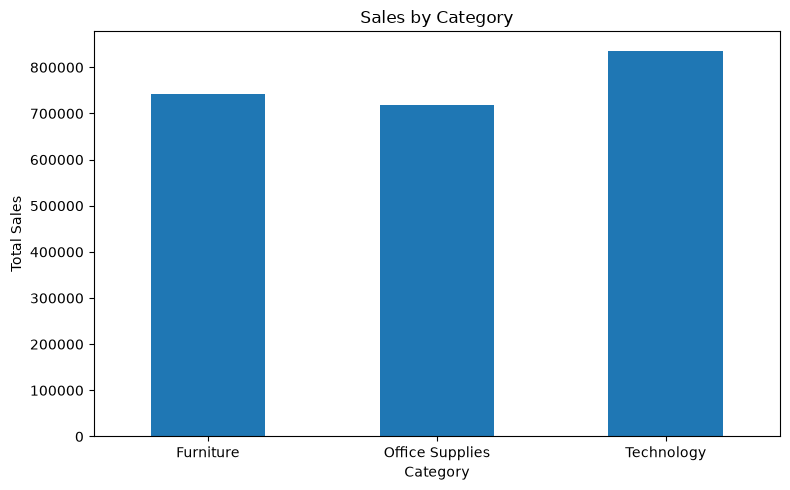

In [70]:
# Chart 1: Sales by Category

import matplotlib.pyplot as plt

category_sales = df.groupby("Category")["Sales"].sum()

plt.figure(figsize=(8, 5))
category_sales.plot(kind="bar")

plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

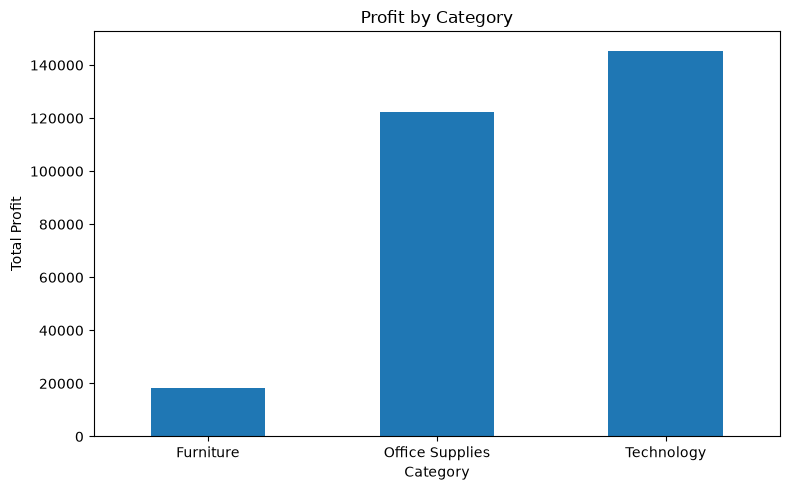

In [71]:
# Chart 2: Profit by Category

category_profit = df.groupby("Category")["Profit"].sum()

plt.figure(figsize=(8, 5))
category_profit.plot(kind="bar")

plt.title("Profit by Category")
plt.xlabel("Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

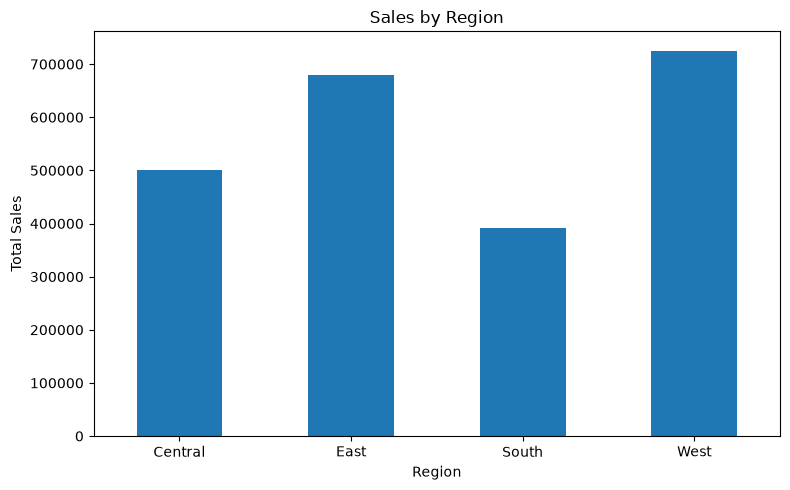

In [72]:
# Chart 3: Sales by Region

region_sales = df.groupby("Region")["Sales"].sum()

plt.figure(figsize=(8, 5))
region_sales.plot(kind="bar")

plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

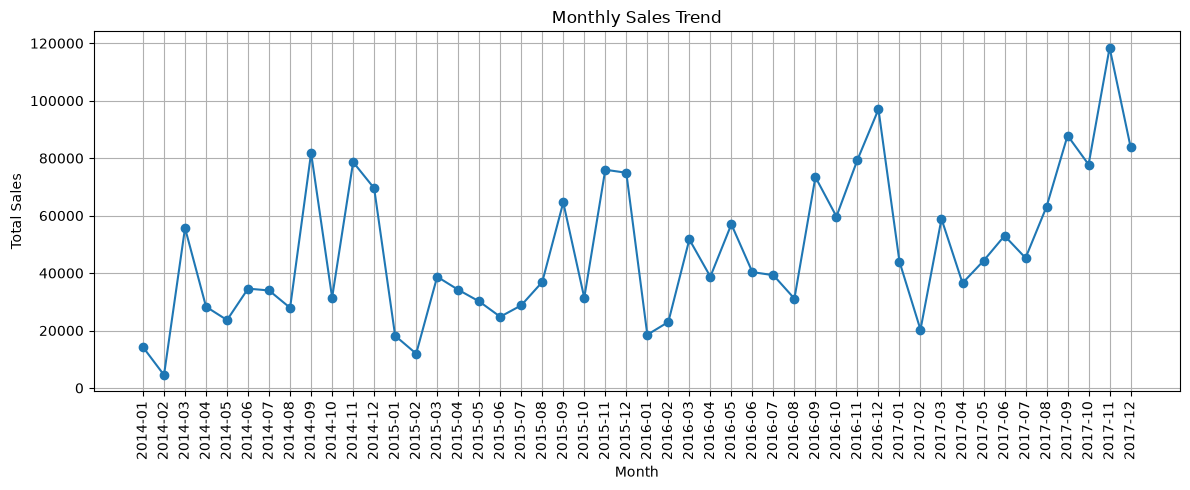

In [73]:
# Chart 4: Monthly Sales Trend

monthly_sales = df.groupby(df["Order Date"].dt.to_period("M"))["Sales"].sum()

plt.figure(figsize=(12, 5))
plt.plot(monthly_sales.index.astype(str), monthly_sales.values, marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()

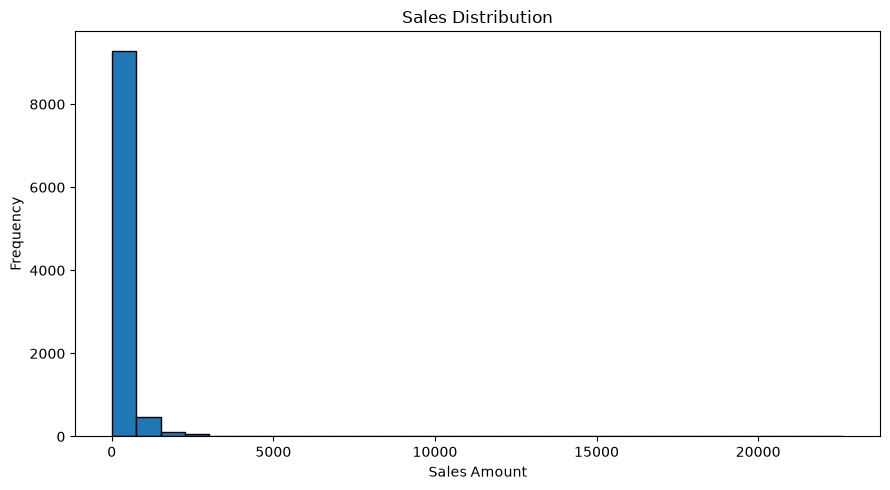

In [74]:
# Chart 5: Sales Distribution

plt.figure(figsize=(9, 5))
plt.hist(df["Sales"], bins=30, edgecolor="black")

plt.title("Sales Distribution")
plt.xlabel("Sales Amount")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

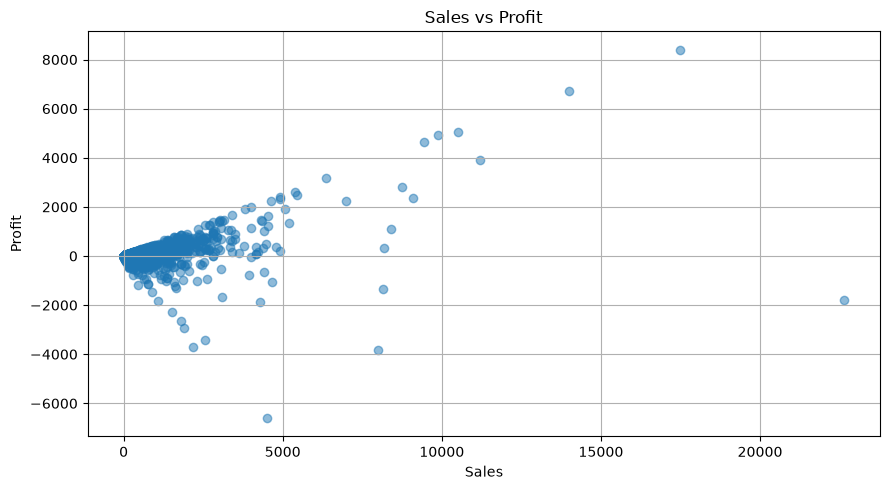

In [75]:
# Chart 6: Sales vs Profit

plt.figure(figsize=(9, 5))

plt.scatter(df["Sales"], df["Profit"], alpha=0.5)

plt.title("Sales vs Profit")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.grid(True)
plt.tight_layout()
plt.show()

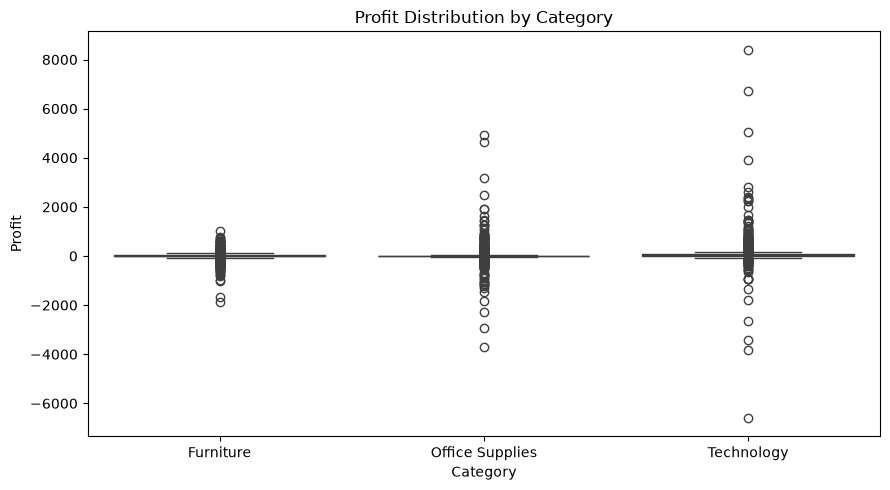

In [76]:
# Chart 7: Profit by Category

import seaborn as sns

plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x="Category", y="Profit")

plt.title("Profit Distribution by Category")
plt.xlabel("Category")
plt.ylabel("Profit")
plt.tight_layout()
plt.show()

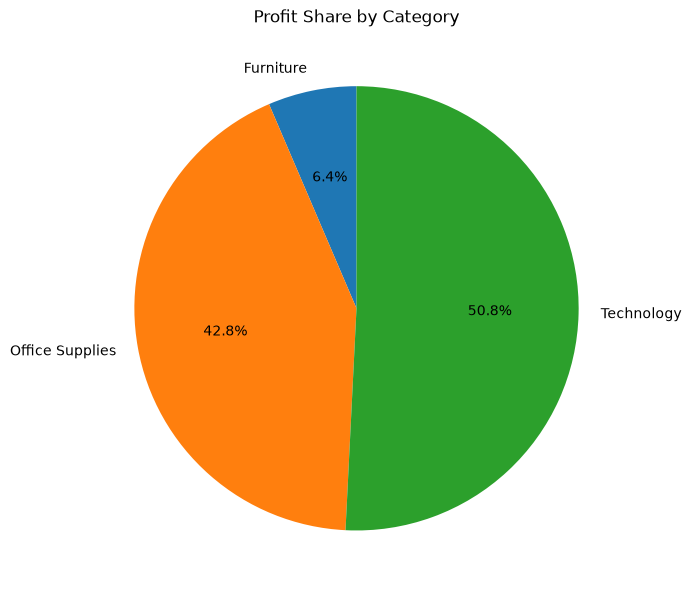

In [77]:
# Chart 8: Profit Share by Category

category_profit = df.groupby("Category")["Profit"].sum()

plt.figure(figsize=(7, 7))

plt.pie(
    category_profit,
    labels=category_profit.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Profit Share by Category")
plt.tight_layout()
plt.show()

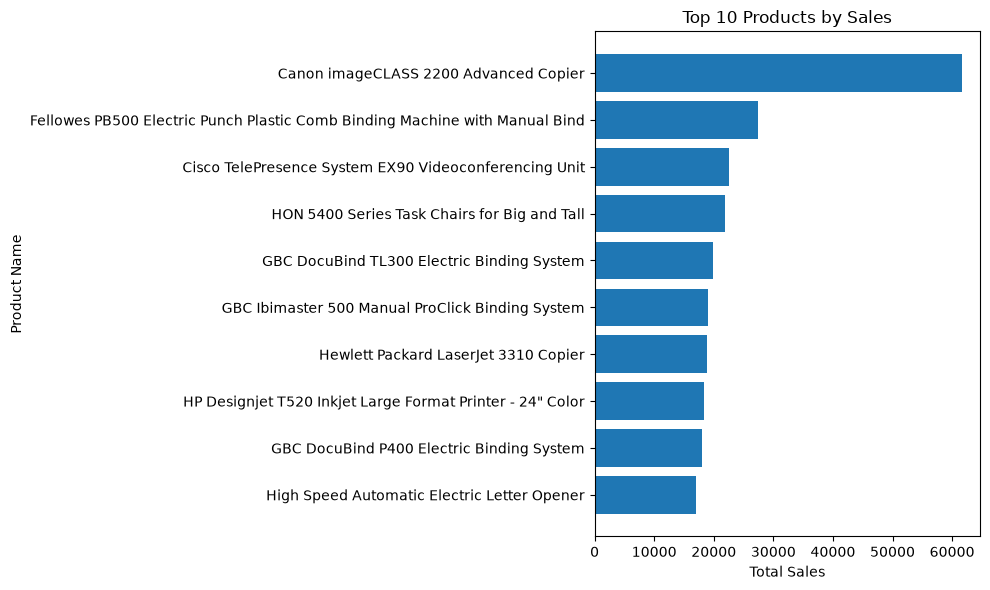

In [78]:
# Chart 9: Top 10 Products by Sales

top_products = df.groupby("Product Name")["Sales"].sum().sort_values(ascending=True).tail(10)

plt.figure(figsize=(10, 6))

plt.barh(top_products.index, top_products.values)

plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product Name")
plt.tight_layout()
plt.show()

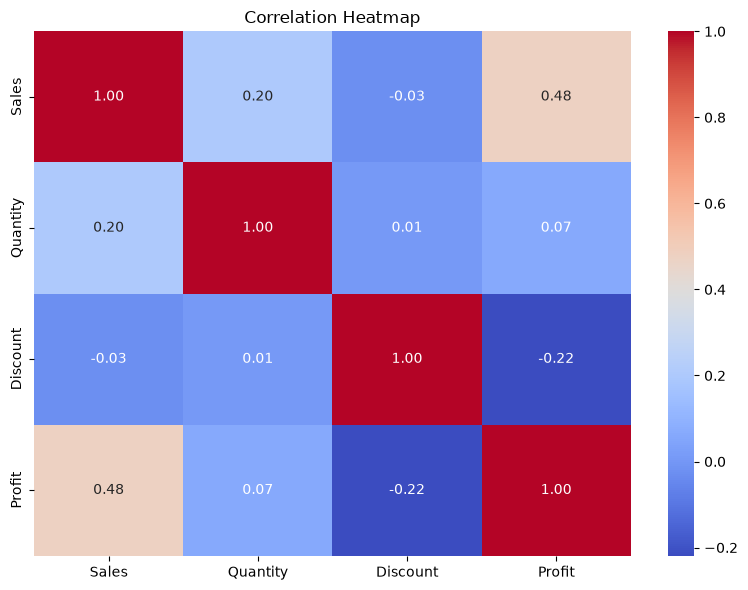

In [79]:
# Chart 10: Correlation Heatmap

numeric_data = df[["Sales", "Quantity", "Discount", "Profit"]]

correlation = numeric_data.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [80]:
# Cell 1: Import Machine Learning Libraries

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Machine Learning libraries imported successfully!")

Machine Learning libraries imported successfully!


In [81]:
# Cell 2: Select Features and Target

X = df[[
    "Sales",
    "Quantity",
    "Discount",
    "Category",
    "Sub-Category",
    "Region",
    "Segment",
    "Ship Mode"
]]

y = df["Profit"]

print("Features selected successfully!")
print("Input shape:", X.shape)
print("Target shape:", y.shape)

Features selected successfully!
Input shape: (9994, 8)
Target shape: (9994,)


In [82]:
# Cell 3: Convert Categorical Columns

X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Categorical columns converted successfully!")
print("New input shape:", X.shape)

X.head()

Categorical columns converted successfully!
New input shape: (9994, 29)


,Sales,Quantity,Discount,Category_Office Supplies,Category_Technology,Sub-Category_Appliances,Sub-Category_Art,Sub-Category_Binders,Sub-Category_Bookcases,Sub-Category_Chairs,...,Sub-Category_Supplies,Sub-Category_Tables,Region_East,Region_South,Region_West,Segment_Corporate,Segment_Home Office,Ship Mode_Same Day,Ship Mode_Second Class,Ship Mode_Standard Class
0,261.9600,2,0.00,0,0,0,0,0,1,0,...,0,0,0,1,0,0,0,0,1,0
1,731.9400,3,0.00,0,0,0,0,0,0,1,...,0,0,0,1,0,0,0,0,1,0
2,14.6200,2,0.00,1,0,0,0,0,0,0,...,0,0,0,0,1,1,0,0,1,0
3,957.5775,5,0.45,0,0,0,0,0,0,0,...,0,1,0,1,0,0,0,0,0,1
4,22.3680,2,0.20,1,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,1


In [83]:
# Cell 4: Split Training and Testing Data

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Data split completed successfully!")
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Data split completed successfully!
Training data: (7995, 29)
Testing data: (1999, 29)


In [84]:
# Cell 5: Train Linear Regression Model

model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression Model trained successfully!")

Linear Regression Model trained successfully!


In [85]:
# Cell 6: Predict Profit

y_pred = model.predict(X_test)

print("Profit prediction completed successfully!")

print("First 10 Actual Profit Values:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Profit Values:")
print(y_pred[:10])

Profit prediction completed successfully!
First 10 Actual Profit Values:
[ 21.1428  11.46    17.158  -15.147   -6.4233   8.6744 -73.7061   8.69
 -15.08    17.908 ]

First 10 Predicted Profit Values:
[  79.00708475   36.54841902   55.96677115  -52.2250822  -152.7791186
    1.4531455   -15.19881777   96.20089035  -81.06472206  -69.24914003]


In [86]:
# Cell 7: Evaluate Model Performance

import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Performance")
print("-------------------------")
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

Model Performance
-------------------------
MAE: 67.8
MSE: 79762.59
RMSE: 282.42
R2 Score: -0.6451


In [87]:
# Cell 8: Actual vs Predicted Profit

comparison = pd.DataFrame({
    "Actual Profit": y_test.values,
    "Predicted Profit": y_pred
})

print(comparison.head(10))

   Actual Profit  Predicted Profit
0        21.1428         79.007085
1        11.4600         36.548419
2        17.1580         55.966771
3       -15.1470        -52.225082
4        -6.4233       -152.779119
5         8.6744          1.453145
6       -73.7061        -15.198818
7         8.6900         96.200890
8       -15.0800        -81.064722
9        17.9080        -69.249140


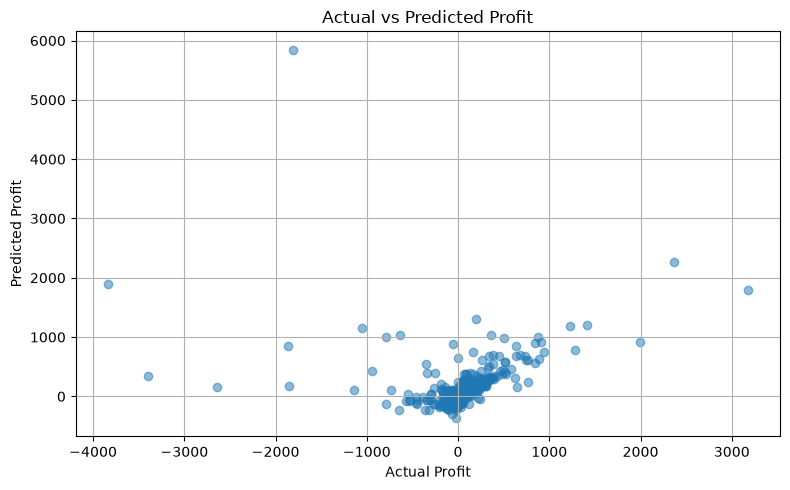

In [88]:
# Cell 9: Actual vs Predicted Profit Visualization

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.title("Actual vs Predicted Profit")
plt.xlabel("Actual Profit")
plt.ylabel("Predicted Profit")
plt.grid(True)
plt.tight_layout()
plt.show()

In [89]:
# Check Actual vs Predicted Profit

print(comparison.head(10))

print("\nActual Profit Statistics:")
print(y_test.describe())

print("\nPredicted Profit Statistics:")
print(pd.Series(y_pred).describe())

   Actual Profit  Predicted Profit
0        21.1428         79.007085
1        11.4600         36.548419
2        17.1580         55.966771
3       -15.1470        -52.225082
4        -6.4233       -152.779119
5         8.6744          1.453145
6       -73.7061        -15.198818
7         8.6900         96.200890
8       -15.0800        -81.064722
9        17.9080        -69.249140

Actual Profit Statistics:
count    1999.000000
mean       20.495678
std       220.248479
min     -3839.990400
25%         1.864400
50%         8.690000
75%        27.400800
max      3177.475000
Name: Profit, dtype: float64

Predicted Profit Statistics:
count    1999.000000
mean       35.791466
std       202.652286
min      -366.355601
25%       -21.477891
50%        19.324140
75%        46.560808
max      5845.694073
dtype: float64


In [90]:
from sklearn.dummy import DummyRegressor

# Create baseline model
baseline_model = DummyRegressor(strategy="mean")

# Train baseline model
baseline_model.fit(X_train, y_train)

# Predict profit
baseline_pred = baseline_model.predict(X_test)

# Evaluate baseline
baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_r2 = r2_score(y_test, baseline_pred)

print("Baseline Model Performance")
print("----------------------------")
print("Baseline MAE:", round(baseline_mae, 2))
print("Baseline R2 Score:", round(baseline_r2, 4))

Baseline Model Performance
----------------------------
Baseline MAE: 67.55
Baseline R2 Score: -0.0021


In [91]:
# Cell 11: Create New Features

X_new = X.copy()

X_new["Sales_Discount"] = df["Sales"] * df["Discount"]
X_new["Sales_Quantity"] = df["Sales"] * df["Quantity"]

print("New features created successfully!")
print("New dataset shape:", X_new.shape)

X_new.head()

New features created successfully!
New dataset shape: (9994, 31)


,Sales,Quantity,Discount,Category_Office Supplies,Category_Technology,Sub-Category_Appliances,Sub-Category_Art,Sub-Category_Binders,Sub-Category_Bookcases,Sub-Category_Chairs,...,Region_East,Region_South,Region_West,Segment_Corporate,Segment_Home Office,Ship Mode_Same Day,Ship Mode_Second Class,Ship Mode_Standard Class,Sales_Discount,Sales_Quantity
0,261.9600,2,0.00,0,0,0,0,0,1,0,...,0,1,0,0,0,0,1,0,0.000000,523.9200
1,731.9400,3,0.00,0,0,0,0,0,0,1,...,0,1,0,0,0,0,1,0,0.000000,2195.8200
2,14.6200,2,0.00,1,0,0,0,0,0,0,...,0,0,1,1,0,0,1,0,0.000000,29.2400
3,957.5775,5,0.45,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,1,430.909875,4787.8875
4,22.3680,2,0.20,1,0,0,0,0,0,0,...,0,1,0,0,0,0,0,1,4.473600,44.7360


In [92]:
# Cell 12: Split Updated Data

X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
    X_new, y,
    test_size=0.2,
    random_state=42
)

print("Updated data split completed!")
print("Training data:", X_train_new.shape)
print("Testing data:", X_test_new.shape)

Updated data split completed!
Training data: (7995, 31)
Testing data: (1999, 31)


In [93]:
# Cell 13: Train Updated Model

model_new = LinearRegression()

model_new.fit(X_train_new, y_train_new)

print("Updated Linear Regression Model trained successfully!")

Updated Linear Regression Model trained successfully!


In [94]:
# Cell 14: Predict Profit

y_pred_new = model_new.predict(X_test_new)

print("Updated Profit Prediction Completed!")

print("First 10 Actual Profit Values:")
print(y_test_new.head(10).values)

print("\nFirst 10 Predicted Profit Values:")
print(y_pred_new[:10])

Updated Profit Prediction Completed!
First 10 Actual Profit Values:
[ 21.1428  11.46    17.158  -15.147   -6.4233   8.6744 -73.7061   8.69
 -15.08    17.908 ]

First 10 Predicted Profit Values:
[ -0.55349254  16.80033511   5.97295285 -57.7684401  -82.01754014
  -0.98055276 -81.37963223  14.06078778  -4.03590122 -23.99426082]


In [95]:
# Cell 15: Evaluate Updated Model

mae_new = mean_absolute_error(y_test_new, y_pred_new)
mse_new = mean_squared_error(y_test_new, y_pred_new)
rmse_new = np.sqrt(mse_new)
r2_new = r2_score(y_test_new, y_pred_new)

print("Updated Model Performance")
print("---------------------------")
print("MAE:", round(mae_new, 2))
print("MSE:", round(mse_new, 2))
print("RMSE:", round(rmse_new, 2))
print("R2 Score:", round(r2_new, 4))

Updated Model Performance
---------------------------
MAE: 40.92
MSE: 31781.19
RMSE: 178.27
R2 Score: 0.3445


In [96]:
# Cell 16: Compare All Models

model_comparison = pd.DataFrame({
    "Model": ["Baseline Model", "Old Linear Regression", "Improved Linear Regression"],
    "MAE": [baseline_mae, mae, mae_new],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, baseline_pred)),
        rmse,
        rmse_new
    ],
    "R2 Score": [baseline_r2, r2, r2_new]
})

print(model_comparison.round(4))

                        Model      MAE      RMSE  R2 Score
0              Baseline Model  67.5473  220.4296   -0.0021
1       Old Linear Regression  67.7951  282.4227   -0.6451
2  Improved Linear Regression  40.9177  178.2728    0.3445


In [97]:
# Final ML Conclusion

print("FINAL MACHINE LEARNING RESULT")
print("------------------------------")
print("Best Model: Improved Linear Regression")
print("MAE:", round(mae_new, 2))
print("RMSE:", round(rmse_new, 2))
print("R2 Score:", round(r2_new, 4))

print("\nFeature Engineering improved model performance.")

FINAL MACHINE LEARNING RESULT
------------------------------
Best Model: Improved Linear Regression
MAE: 40.92
RMSE: 178.27
R2 Score: 0.3445

Feature Engineering improved model performance.


In [99]:
import joblib
import os

joblib.dump(model_new, "profit_prediction_model.pkl")
joblib.dump(X_new.columns.tolist(), "model_columns.pkl")

print("Model and columns saved successfully!")

Model and columns saved successfully!


In [100]:
import os

print(os.path.getsize("profit_prediction_model.pkl"))
print(os.path.getsize("model_columns.pkl"))

1999
660
